# Random Under Sampling

## Without Using Imblearn

In [133]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification,make_blobs
from sklearn.utils import shuffle
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import NeighbourhoodCleaningRule
from imblearn.under_sampling import ClusterCentroids

In [134]:
# Create a synthetic dataset with imbalance
X, y = make_classification(
    n_samples=100000,
    n_features=20,
    weights=[0.95, 0.05],
    random_state=42
)

In [135]:
# Create a DataFrame with the data
df = pd.DataFrame(X)
df['target'] = y

In [136]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,target
0,0.328547,-1.384724,-0.284819,-0.030196,-0.840365,-1.012684,-1.297740,-0.046200,0.744777,-1.843827,...,-0.653045,0.944825,0.732865,-0.198004,-0.664024,-0.230734,-0.355199,-1.165488,2.073555,0
1,0.801869,2.390928,-1.232367,1.144513,-1.031983,0.742784,-1.287784,-0.639615,-1.332604,-0.708368,...,-0.969296,-0.338274,0.064910,-0.904066,-0.245746,1.021368,0.074146,1.120685,1.605930,0
2,-0.674526,-0.261000,-0.464924,-1.495308,-1.888075,0.064322,0.541989,-2.489174,1.023665,-2.289584,...,-1.666518,0.521572,-0.487614,-0.020727,0.034012,-1.341455,-0.368306,0.420709,0.096521,0
3,-1.188735,1.100929,0.818446,-0.573651,-0.777052,1.706128,-0.929116,-0.520684,-0.677726,-1.600877,...,-0.615035,0.062205,0.436514,1.303629,1.340363,-1.203694,-0.568942,-0.907041,-0.460908,0
4,-1.227908,-0.617620,-0.104353,0.986159,-0.763533,1.249342,-1.105068,-0.516500,-2.200517,-1.589052,...,-0.602610,-1.186905,-1.399522,-0.721840,0.657838,0.139794,-0.212828,-0.917548,-1.022671,0


In [137]:
df['target'].value_counts()

target
0    94542
1     5458
Name: count, dtype: int64

In [138]:

# Split the dataset into majority and minority classes
majority_df = df[df['target'] == 0]
minority_df = df[df['target'] == 1]

In [139]:
# Apply random undersampling to the majority class
undersampled_majority_df = majority_df.sample(n=minority_df.shape[0], random_state=42)

# Combine the undersampled majority class with the minority class
undersampled_df = pd.concat([undersampled_majority_df, minority_df])

# Shuffle the resulting DataFrame to avoid any order bias
undersampled_df = shuffle(undersampled_df, random_state=42)

In [140]:
undersampled_df['target'].value_counts()

target
0    5458
1    5458
Name: count, dtype: int64

In [141]:
X = undersampled_df.drop(columns=['target'])
y = undersampled_df['target']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [142]:
# Train a simple logistic regression model
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
classification_report_str = classification_report(y_test, y_pred)

In [143]:
# Display results
print("Accuracy:", accuracy)

Accuracy: 0.8290076335877863


In [144]:
confusion

array([[1358,  262],
       [ 298, 1357]])

In [145]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      1620
           1       0.84      0.82      0.83      1655

    accuracy                           0.83      3275
   macro avg       0.83      0.83      0.83      3275
weighted avg       0.83      0.83      0.83      3275



## Using Imblearn

In [146]:
# Create a synthetic dataset with imbalance
X, y = make_classification(
    n_samples=100000,
    n_features=20,
    weights=[0.95, 0.05],  # Class imbalance
    random_state=42
)

# Check the original class distribution
print("Original class distribution:", Counter(y))

Original class distribution: Counter({np.int64(0): 94542, np.int64(1): 5458})


In [147]:
# Use RandomUnderSampler to balance the dataset
undersampler = RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = undersampler.fit_resample(X, y)

# Check the new class distribution after undersampling
print("New class distribution after undersampling:", Counter(y_resampled))

New class distribution after undersampling: Counter({np.int64(0): 5458, np.int64(1): 5458})


In [148]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42)

In [149]:
# Train a simple logistic regression model
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)
classification_report_str = classification_report(y_test, y_pred)

In [150]:
print(classification_report_str)

              precision    recall  f1-score   support

           0       0.82      0.82      0.82      1648
           1       0.82      0.82      0.82      1627

    accuracy                           0.82      3275
   macro avg       0.82      0.82      0.82      3275
weighted avg       0.82      0.82      0.82      3275



# Tomek Links

1. It is a technique which is used for clearing decision boundary. It is used with other algorithms such as SMOTE , etc..

2. Though it is used for removing the data points , but it is not entirely an undersampling technique because the imbalance still persists.

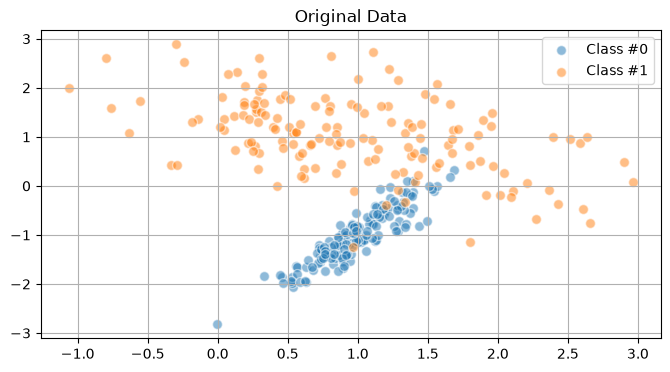

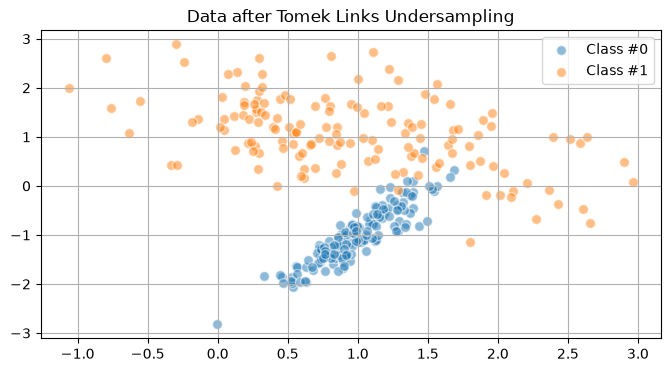

In [151]:
# Generate a synthetic dataset with overlap
X, y = make_classification(n_classes=2, class_sep=1, # class_sep controls the separability of the classes
                           weights=[0.5, 0.5], n_informative=2, n_redundant=0, flip_y=0,
                           n_features=2, n_clusters_per_class=1, n_samples=300, random_state=42)

# Plotting function to visualize the data
def plot_data(X, y, title):
    plt.figure(figsize=(8, 4))
    plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], label="Class #0", alpha=0.5, edgecolors='w', s=50)
    plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], label="Class #1", alpha=0.5, edgecolors='w', s=50)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

# Original data plot
plot_data(X, y, "Original Data")

# Applying Tomek Links
tl = TomekLinks()
X_res, y_res = tl.fit_resample(X, y)

# Resampled data plot
plot_data(X_res, y_res, "Data after Tomek Links Undersampling")

In [152]:
X.shape

(300, 2)

In [153]:
X_res.shape

(296, 2)

### Only 4 data points have been removed.

# Edited Nearest Neighbour.

1. Equivalent to tomek links , but it is KNN (default = 3) to remove the points. If any of the k neighbour is minority then it is removed. (if the hp is set to 'all'). 

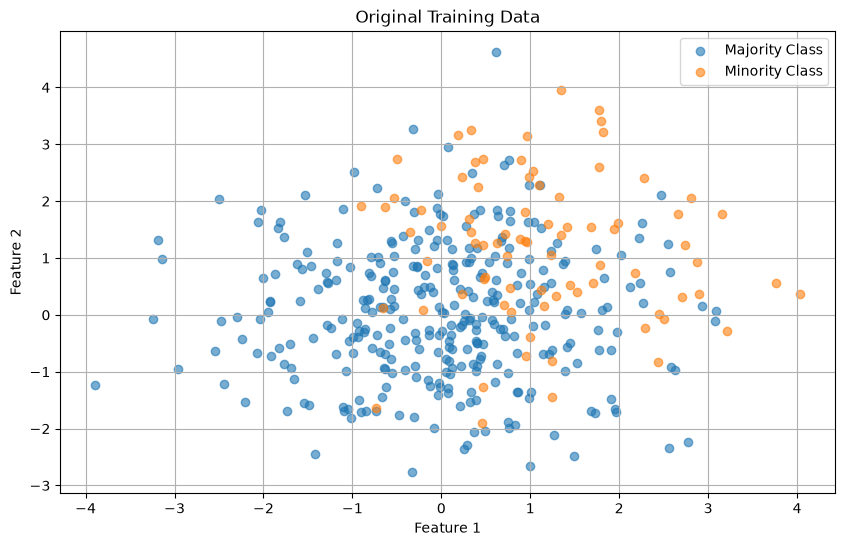

In [154]:
# Generate a synthetic imbalanced binary dataset with make_blobs
# Adjust the centers and standard deviation to reduce the gap and create some overlap
X, y = make_blobs(n_samples=[400, 100], centers=[[0, 0], [1, 1]], cluster_std=1.2, random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Plot original data
plt.figure(figsize=(10, 6))
plt.scatter(X_train[y_train == 0][:, 0], X_train[y_train == 0][:, 1], label='Majority Class', alpha=0.6)
plt.scatter(X_train[y_train == 1][:, 0], X_train[y_train == 1][:, 1], label='Minority Class', alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

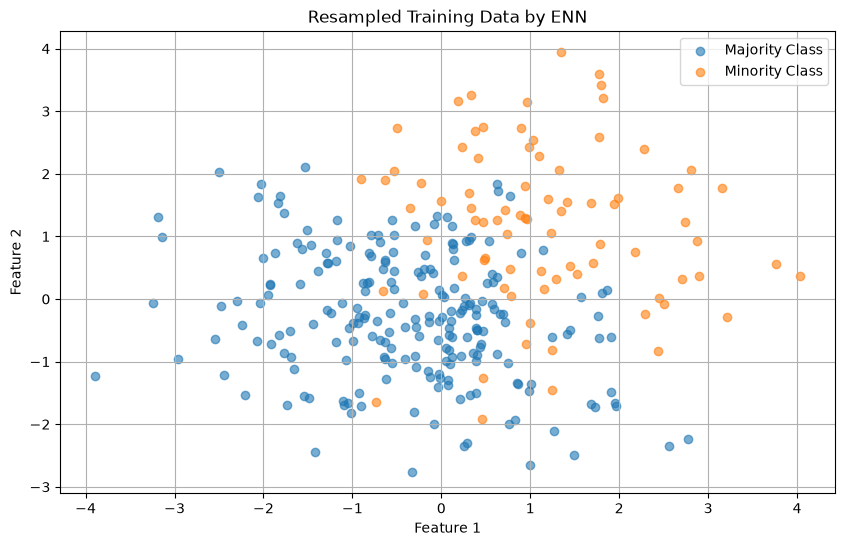

In [155]:
# Apply Edited Nearest Neighbours
enn = EditedNearestNeighbours()
X_resampled, y_resampled = enn.fit_resample(X_train, y_train)

# Plot resampled data
plt.figure(figsize=(10, 6))
plt.scatter(X_resampled[y_resampled == 0][:, 0], X_resampled[y_resampled == 0][:, 1], label='Majority Class', alpha=0.6)
plt.scatter(X_resampled[y_resampled == 1][:, 0], X_resampled[y_resampled == 1][:, 1], label='Minority Class', alpha=0.6)
plt.title('Resampled Training Data by ENN')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

In [156]:
X_train.shape

(400, 2)

In [157]:
X_resampled.shape

(300, 2)

In [158]:
pd.Series(y_train).value_counts()

0    319
1     81
Name: count, dtype: int64

In [159]:
# Train a classifier on the resampled data
lr = LogisticRegression()
lr.fit(X_train, y_train)

# Test the classifier
y_pred = lr.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.96      0.91        81
           1       0.67      0.32      0.43        19

    accuracy                           0.84       100
   macro avg       0.76      0.64      0.67       100
weighted avg       0.82      0.84      0.82       100



In [160]:
# Train a classifier on the resampled data
lr = LogisticRegression()
lr.fit(X_resampled, y_resampled)

# Test the classifier
y_pred = lr.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.85      0.88        81
           1       0.52      0.68      0.59        19

    accuracy                           0.82       100
   macro avg       0.72      0.77      0.74       100
weighted avg       0.84      0.82      0.83       100



# Neighborhood Cleaning Rule

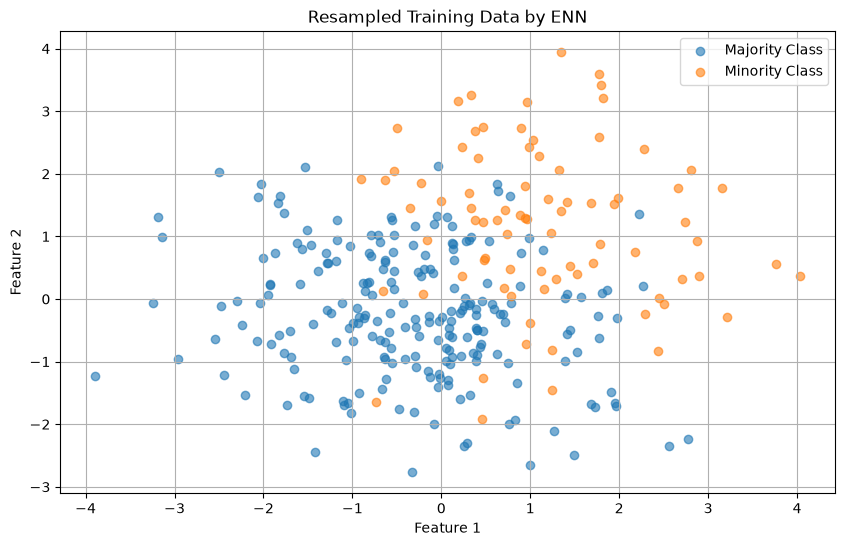

In [161]:
ncr = NeighbourhoodCleaningRule()
X_resampled, y_resampled = ncr.fit_resample(X_train, y_train)

# Plot resampled data
plt.figure(figsize=(10, 6))
plt.scatter(X_resampled[y_resampled == 0][:, 0], X_resampled[y_resampled == 0][:, 1], label='Majority Class', alpha=0.6)
plt.scatter(X_resampled[y_resampled == 1][:, 0], X_resampled[y_resampled == 1][:, 1], label='Minority Class', alpha=0.6)
plt.title('Resampled Training Data by ENN')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

In [162]:
X_resampled.shape

(303, 2)

In [163]:
pd.Series(y_resampled).value_counts()

0    222
1     81
Name: count, dtype: int64

In [164]:
# Train a classifier on the resampled data
lr = LogisticRegression()
lr.fit(X_resampled, y_resampled)

# Test the classifier
y_pred = lr.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.89        81
           1       0.55      0.63      0.59        19

    accuracy                           0.83       100
   macro avg       0.73      0.75      0.74       100
weighted avg       0.84      0.83      0.83       100



# Custer Centroids

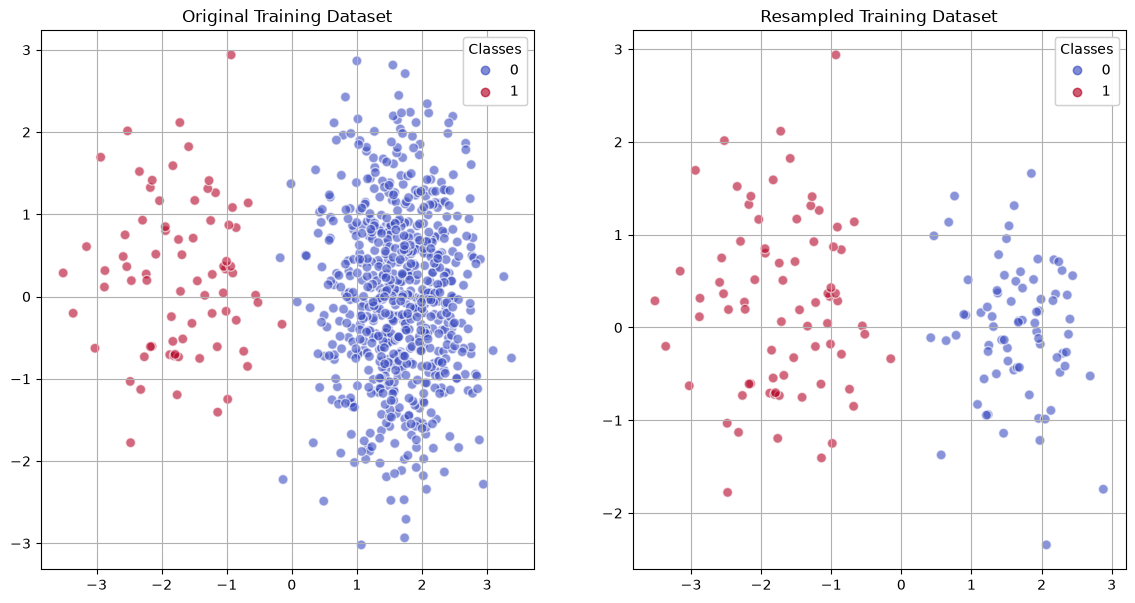

In [165]:
# Generate a synthetic imbalanced dataset with 2 informative, 1 redundant, and 0 repeated features
X, y = make_classification(n_classes=2, class_sep=2,
                           weights=[0.9, 0.1], n_informative=2, n_redundant=1, flip_y=0,
                           n_features=20, n_clusters_per_class=1, n_samples=1000, random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Plotting function to plot the classes
def plot_classes(X, y, subplot, title):
    ax = plt.subplot(subplot)
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', alpha=0.6, edgecolors='w', s=50)
    plt.title(title)
    plt.grid(True)
    legends = ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    ax.add_artist(legends)

# Create a figure with 2 subplots (side by side)
plt.figure(figsize=(14, 7))

# Plot original distribution
plot_classes(X_train, y_train, 121, "Original Training Dataset")  # 121 means 1 row, 2 columns, 1st subplot

# Apply Cluster Centroids undersampling
cc = ClusterCentroids(random_state=42)
X_resampled, y_resampled = cc.fit_resample(X_train, y_train)

# Plot resampled distribution
plot_classes(X_resampled, y_resampled, 122, "Resampled Training Dataset")  # 122 means 1 row, 2 columns, 2nd subplot

plt.show()

In [166]:
X_train.shape, X_resampled.shape

((750, 20), (150, 20))

In [167]:
pd.Series(y_train).value_counts()

0    675
1     75
Name: count, dtype: int64

In [168]:
pd.Series(y_resampled).value_counts()

0    75
1    75
Name: count, dtype: int64